# 07 · Inspect clean nested metadata tuning

Reproduce the historical bounded searches and their patient-safe evaluation. Show every candidate, reconstructed inner membership, selected setting, fixed-versus-tuned curve and fold-level change.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [07_metadata_tuning.ipynb](../Subset/07_metadata_tuning.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '07_metadata_tuning'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Load scores and declare the exact bounded search

Inside each outer-training pool, mean AP across three inner patient folds selects a setting. Grid order resolves ties deterministically, and a fresh fit on all outer-training patients supplies the outer prediction. Candidate counts are 18 spline, 12 forest and 12 XGBoost; 630 inner fits plus 15 selected outer refits. Fixed comparator fits are reused.

In [2]:
import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))

from melanoma_detection.dedup_metadata_suite import GRIDS
from sklearn.model_selection import ParameterGrid
grid_rows = [{"model": name, "parameter": parameter.rsplit("__", 1)[-1], "values": str(values), "candidate_recipes": len(list(ParameterGrid(grid)))} for name, grid in GRIDS.items() for parameter, values in grid.items()]
display(pd.DataFrame(grid_rows))
selected = pd.read_csv(meta["suite"] / "selected_parameters.csv")
candidates = pd.read_csv(meta["suite"] / "inner_candidates.csv")
families = [("spline_raw", "spline_tuned"), ("random_forest", "random_forest_tuned"), ("xgboost", "xgboost_tuned")]
names = [name for pair in families for name in pair]
metrics = metric_table(frame, scores, names)

,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


,model,parameter,values,candidate_recipes
0,spline,C,"[0.1, 1.0, 10.0]",18
1,spline,n_knots,"[3, 4, 5]",18
2,spline,degree,"[2, 3]",18
3,random_forest,max_depth,"[4, 8, None]",12
4,random_forest,min_samples_leaf,"[5, 15]",12
5,random_forest,max_features,"['sqrt', 1.0]",12
6,xgboost,max_depth,"[2, 3]",12
7,xgboost,learning_rate,"[0.03, 0.05, 0.1]",12
8,xgboost,min_child_weight,"[1, 5]",12


## 2. Verify reconstruction and inner patient support

No historical tuning membership receipt was saved. The separate reconstruction applies the original seed 42 + outer fold to original 6,864-row CSV order, freezes patient memberships, then retains the clean IDs. It is recorded with library versions and is not represented as a recovered execution receipt. Never regenerate the split on the 6,706 retained rows.

,status,historical_membership_receipt_available,original_row_order_used,split_on_retained_rows,seed_rule
0,reconstructed_and_frozen,False,True,False,42 + outer_fold


,0
python,3.14.6
numpy,2.5.2
pandas,3.0.5
scikit_learn,1.9.0
xgboost,3.4.1
joblib,1.5.3


,outer_fold,inner_fold,fit_images,validation_images,fit_patients,validation_patients,fit_positive_images,validation_positive_images,patient_overlap,outer_patient_overlap
0,0,0,3528,1834,225,113,70,33,0,0
1,0,1,3658,1704,227,111,68,35,0,0
2,0,2,3538,1824,224,114,68,35,0,0
3,1,0,3528,1812,225,113,66,35,0,0
4,1,1,3634,1706,225,113,69,32,0,0
5,1,2,3518,1822,226,112,67,34,0,0
6,2,0,3564,1814,226,109,67,34,0,0
7,2,1,3602,1776,224,111,68,33,0,0
8,2,2,3590,1788,220,115,67,34,0,0
9,3,0,3532,1803,226,114,68,34,0,0


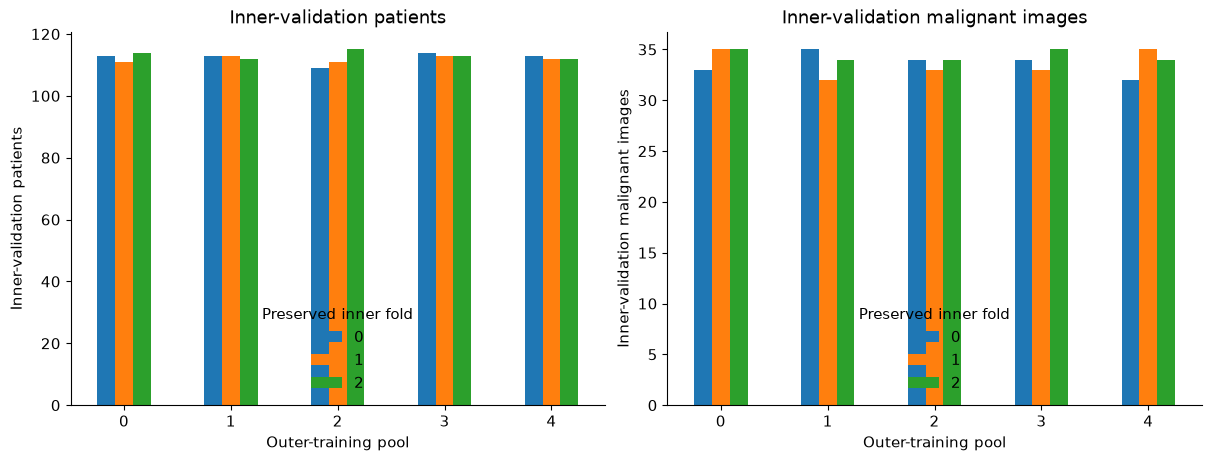

In [3]:
receipt = read_json(meta["suite"] / "memberships_receipt.json")
display(pd.DataFrame([{key: receipt[key] for key in ["status", "historical_membership_receipt_available", "original_row_order_used", "split_on_retained_rows", "seed_rule"]}]))
display(pd.DataFrame([receipt["versions"]]).T)
members = pd.read_csv(meta["suite"] / "inner_memberships_retained.csv")
assert members.groupby(["outer_fold", "patient_id"]).inner_fold.nunique().eq(1).all()
inner_audit = pd.read_csv(meta["suite"] / "inner_audit.csv")
assert inner_audit.patient_overlap.eq(0).all() and inner_audit.outer_patient_overlap.eq(0).all()
display(inner_audit)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, column, label in zip(axes, ["validation_patients", "validation_positive_images"], ["Inner-validation patients", "Inner-validation malignant images"]):
    table = inner_audit.pivot(index="outer_fold", columns="inner_fold", values=column)
    table.plot.bar(ax=ax, rot=0)
    ax.set(title=label, xlabel="Outer-training pool", ylabel=label)
    ax.legend(title="Preserved inner fold", frameon=False)
finish_figure(fig, "nested_inner_patient_and_case_support")

## 3. Inspect selected settings and every candidate

The complete 210-row table contains 42 recipes per outer pool, their three inner AP values, mean, spread and selected flag. These are training-only selection scores, not final OOF performance. The error bars below are standard deviation across three inner folds and are not confidence intervals.

,outer_fold,model,inner_best_average_precision,best_candidate_index,best_parameters
0,0,spline,0.053470,2,"{""classifier__C"": 0.1, ""preprocessor__smooth_a..."
1,0,random_forest,0.046931,1,"{""classifier__max_depth"": 4, ""classifier__max_..."
2,0,xgboost,0.045778,6,"{""classifier__learning_rate"": 0.05, ""classifie..."
3,1,spline,0.064980,2,"{""classifier__C"": 0.1, ""preprocessor__smooth_a..."
4,1,random_forest,0.062906,9,"{""classifier__max_depth"": null, ""classifier__m..."
5,1,xgboost,0.054674,2,"{""classifier__learning_rate"": 0.03, ""classifie..."
6,2,spline,0.077252,7,"{""classifier__C"": 1.0, ""preprocessor__smooth_a..."
7,2,random_forest,0.072754,2,"{""classifier__max_depth"": 4, ""classifier__max_..."
8,2,xgboost,0.075964,8,"{""classifier__learning_rate"": 0.1, ""classifier..."
9,3,spline,0.060540,3,"{""classifier__C"": 0.1, ""preprocessor__smooth_a..."


,outer_fold,model,candidate_index,parameters,mean_inner_average_precision,std_inner_average_precision,mean_fit_seconds,selected,inner_0_average_precision,inner_1_average_precision,inner_2_average_precision
18,0,random_forest,0,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04487,0.01293,0.68813,False,0.03905,0.06279,0.03276
19,0,random_forest,1,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04693,0.01555,0.68855,True,0.03845,0.06874,0.03360
20,0,random_forest,2,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04145,0.01288,0.64329,False,0.03554,0.05933,0.02950
21,0,random_forest,3,"{""classifier__max_depth"": 4, ""classifier__max_...",0.04641,0.01438,0.64956,False,0.03827,0.06662,0.03435
22,0,random_forest,4,"{""classifier__max_depth"": 8, ""classifier__max_...",0.04089,0.01302,0.64560,False,0.03397,0.05913,0.02957
23,0,random_forest,5,"{""classifier__max_depth"": 8, ""classifier__max_...",0.04587,0.01343,0.71489,False,0.04012,0.06441,0.03307
24,0,random_forest,6,"{""classifier__max_depth"": 8, ""classifier__max_...",0.03509,0.01070,0.66111,False,0.03082,0.04980,0.02464
25,0,random_forest,7,"{""classifier__max_depth"": 8, ""classifier__max_...",0.03755,0.00661,0.64978,False,0.03955,0.04447,0.02864
26,0,random_forest,8,"{""classifier__max_depth"": null, ""classifier__m...",0.03673,0.01176,0.64771,False,0.03318,0.05258,0.02443
27,0,random_forest,9,"{""classifier__max_depth"": null, ""classifier__m...",0.04237,0.01088,0.64409,False,0.04019,0.05664,0.03026


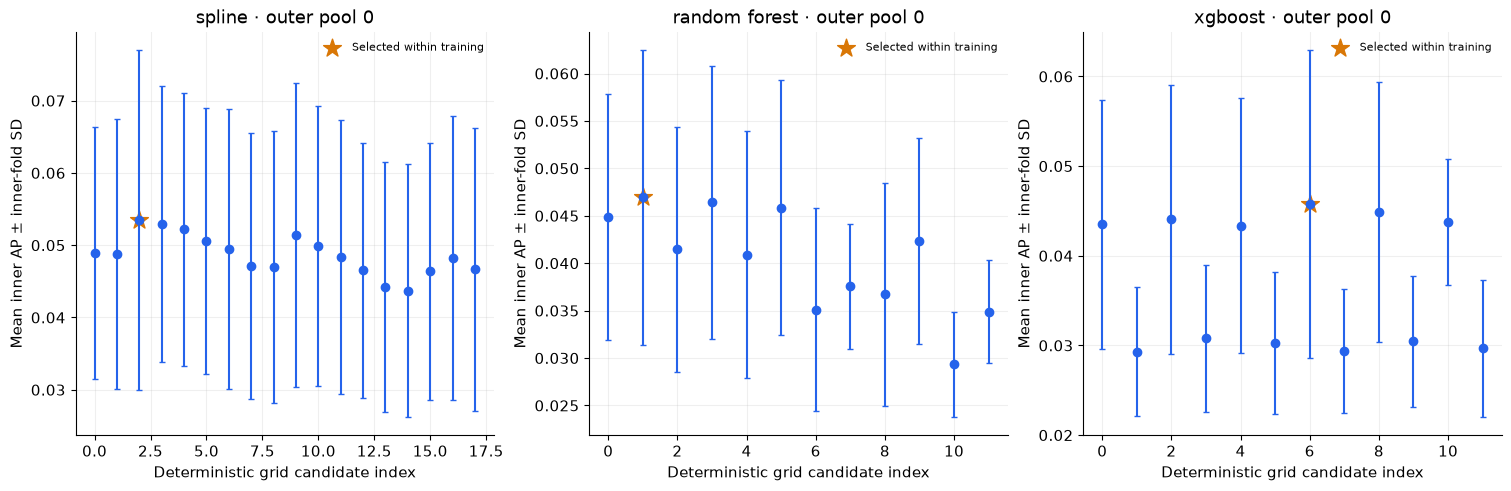

In [4]:
display(selected)
display(candidates.loc[candidates.outer_fold.eq(0)].sort_values(["model", "candidate_index"]).round(5))
assert len(candidates) == 210 and int(candidates.selected.sum()) == 15
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
for ax, model in zip(axes, ["spline", "random_forest", "xgboost"]):
    rows = candidates.loc[candidates.outer_fold.eq(0) & candidates.model.eq(model)]
    ax.errorbar(rows.candidate_index, rows.mean_inner_average_precision, yerr=rows.std_inner_average_precision, fmt="o", color="#2563eb", capsize=2)
    winner = rows.loc[rows.selected]
    ax.scatter(winner.candidate_index, winner.mean_inner_average_precision, marker="*", s=180, color="#d97706", label="Selected within training")
    ax.set(title=model.replace("_", " ") + " · outer pool 0", xlabel="Deterministic grid candidate index", ylabel="Mean inner AP ± inner-fold SD")
    ax.grid(alpha=.2); ax.legend(frameon=False, fontsize=8)
finish_figure(fig, "nested_all_candidate_scores_outer0")

## 4. Check how often each recipe was selected

Different training pools can choose different settings because malignant support is limited. Frequency describes selection stability; it does not identify a single recipe to refit on all development data or retrospectively change this experiment.

,model,best_parameters,outer_pools_selected
0,random_forest,"{""classifier__max_depth"": 4, ""classifier__max_...",3
1,random_forest,"{""classifier__max_depth"": 4, ""classifier__max_...",1
2,random_forest,"{""classifier__max_depth"": null, ""classifier__m...",1
3,spline,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",3
4,spline,"{""classifier__C"": 0.1, ""preprocessor__smooth_a...",1
5,spline,"{""classifier__C"": 1.0, ""preprocessor__smooth_a...",1
6,xgboost,"{""classifier__learning_rate"": 0.03, ""classifie...",1
7,xgboost,"{""classifier__learning_rate"": 0.03, ""classifie...",1
8,xgboost,"{""classifier__learning_rate"": 0.05, ""classifie...",1
9,xgboost,"{""classifier__learning_rate"": 0.05, ""classifie...",1


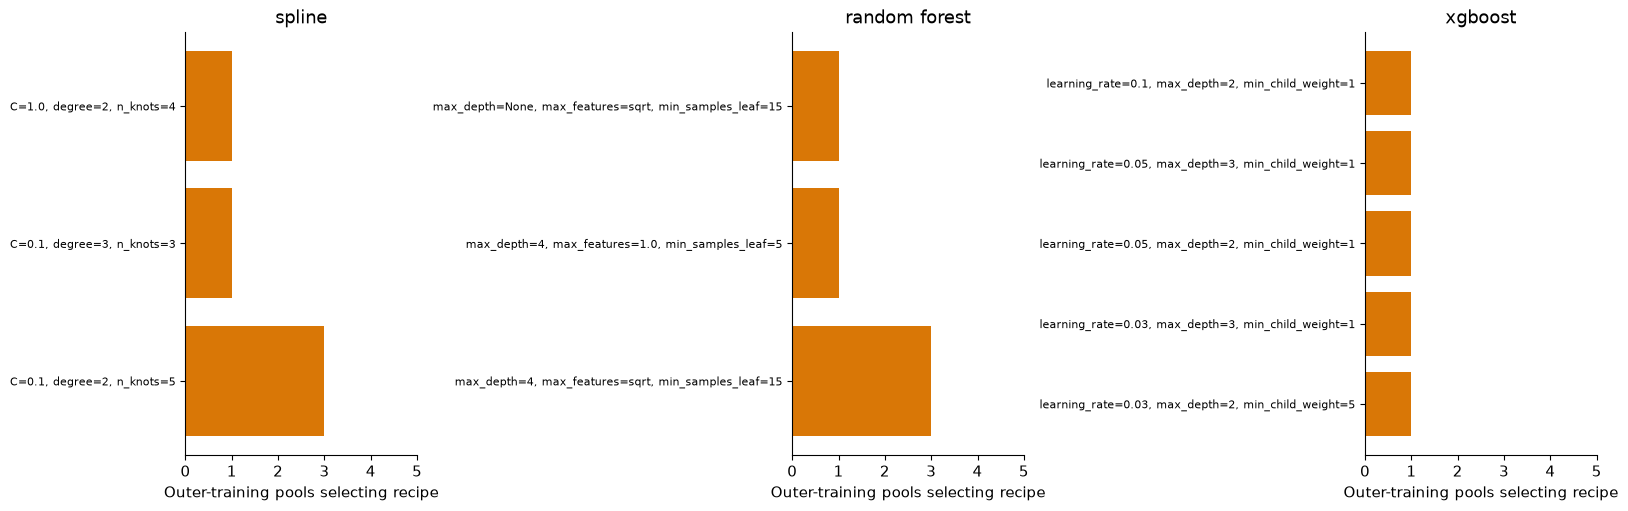

In [5]:
frequency = selected.groupby(["model", "best_parameters"]).size().reset_index(name="outer_pools_selected")
display(frequency)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")
for ax, model in zip(axes, ["spline", "random_forest", "xgboost"]):
    rows = frequency.loc[frequency.model.eq(model)]
    labels = [", ".join(key.rsplit("__", 1)[-1] + "=" + str(value) for key, value in json.loads(parameters).items()) for parameters in rows.best_parameters]
    ax.barh(labels, rows.outer_pools_selected, color="#d97706")
    ax.set(title=model.replace("_", " "), xlabel="Outer-training pools selecting recipe", xlim=(0, 5))
    ax.tick_params(axis="y", labelsize=8)
finish_figure(fig, "nested_recipe_selection_frequency")

## 5. Compare fixed and tuned ranking scores

Use mean-fold AP first and inspect AUC beside it. A tuned procedure can score worse on held-out patients even when its grid contains the fixed setting: it selects by noisy inner AP. Wider tuned-versus-fixed comparisons remain secondary; higher observed AP is not automatic promotion.

,model,scope,fold,average_precision,roc_auc,log_loss,brier
5,spline_raw,mean_fold,NaN,0.06484,0.65563,0.09101,0.01842
6,spline_raw,pooled,NaN,0.04921,0.64283,0.09095,0.01841
12,spline_tuned,mean_fold,NaN,0.06881,0.64303,0.09115,0.01840
13,spline_tuned,pooled,NaN,0.05021,0.63317,0.09111,0.01839
19,random_forest,mean_fold,NaN,0.05477,0.60319,0.09195,0.01845
20,random_forest,pooled,NaN,0.04333,0.60331,0.09189,0.01844
26,random_forest_tuned,mean_fold,NaN,0.05205,0.62673,0.09222,0.01849
27,random_forest_tuned,pooled,NaN,0.04057,0.61406,0.09218,0.01848
33,xgboost,mean_fold,NaN,0.05907,0.59304,0.09385,0.01851
34,xgboost,pooled,NaN,0.04339,0.58930,0.09376,0.01850


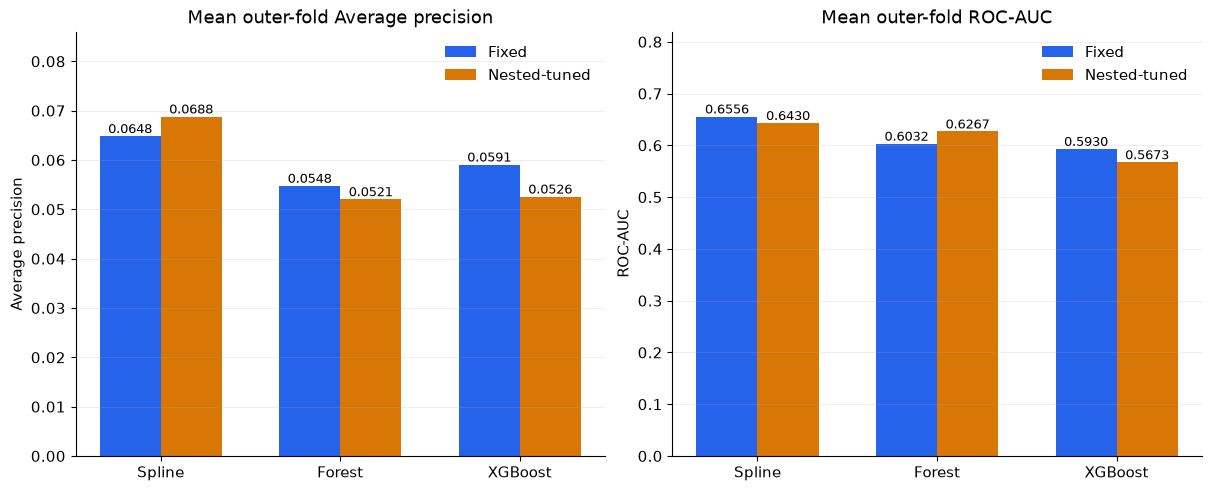

In [6]:
display(metrics.loc[metrics.scope.ne("fold")].round(5))
mean = metrics.loc[metrics.scope.eq("mean_fold")].set_index("model")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
x = np.arange(3)
for ax, metric, label in zip(axes, ["average_precision", "roc_auc"], ["Average precision", "ROC-AUC"]):
    for offset, version, color in [(-.17, 0, "#2563eb"), (.17, 1, "#d97706")]:
        values = [mean.loc[pair[version], metric] for pair in families]
        ax.bar(x + offset, values, width=.34, color=color, label="Fixed" if version == 0 else "Nested-tuned")
        for position, value in zip(x + offset, values): ax.text(position, value, f"{value:.4f}", ha="center", va="bottom", fontsize=9)
    ax.set(xticks=x, xticklabels=["Spline", "Forest", "XGBoost"], ylabel=label, title="Mean outer-fold " + label, ylim=(0, float(mean[metric].max()) * 1.25))
    ax.legend(frameon=False); ax.grid(axis="y", alpha=.2)
finish_figure(fig, "nested_fixed_versus_tuned_scores")

## 6. Read the six pooled ROC and PR comparisons

Each row compares one model family. Dashed blue is fixed and solid gold is tuned. PR precision is focused to 0–30%; AP calculations still use the full ranking. Crossing curves indicate cutoff-dependent trade-offs. Pooled curves are secondary to the mean-fold ranking table.

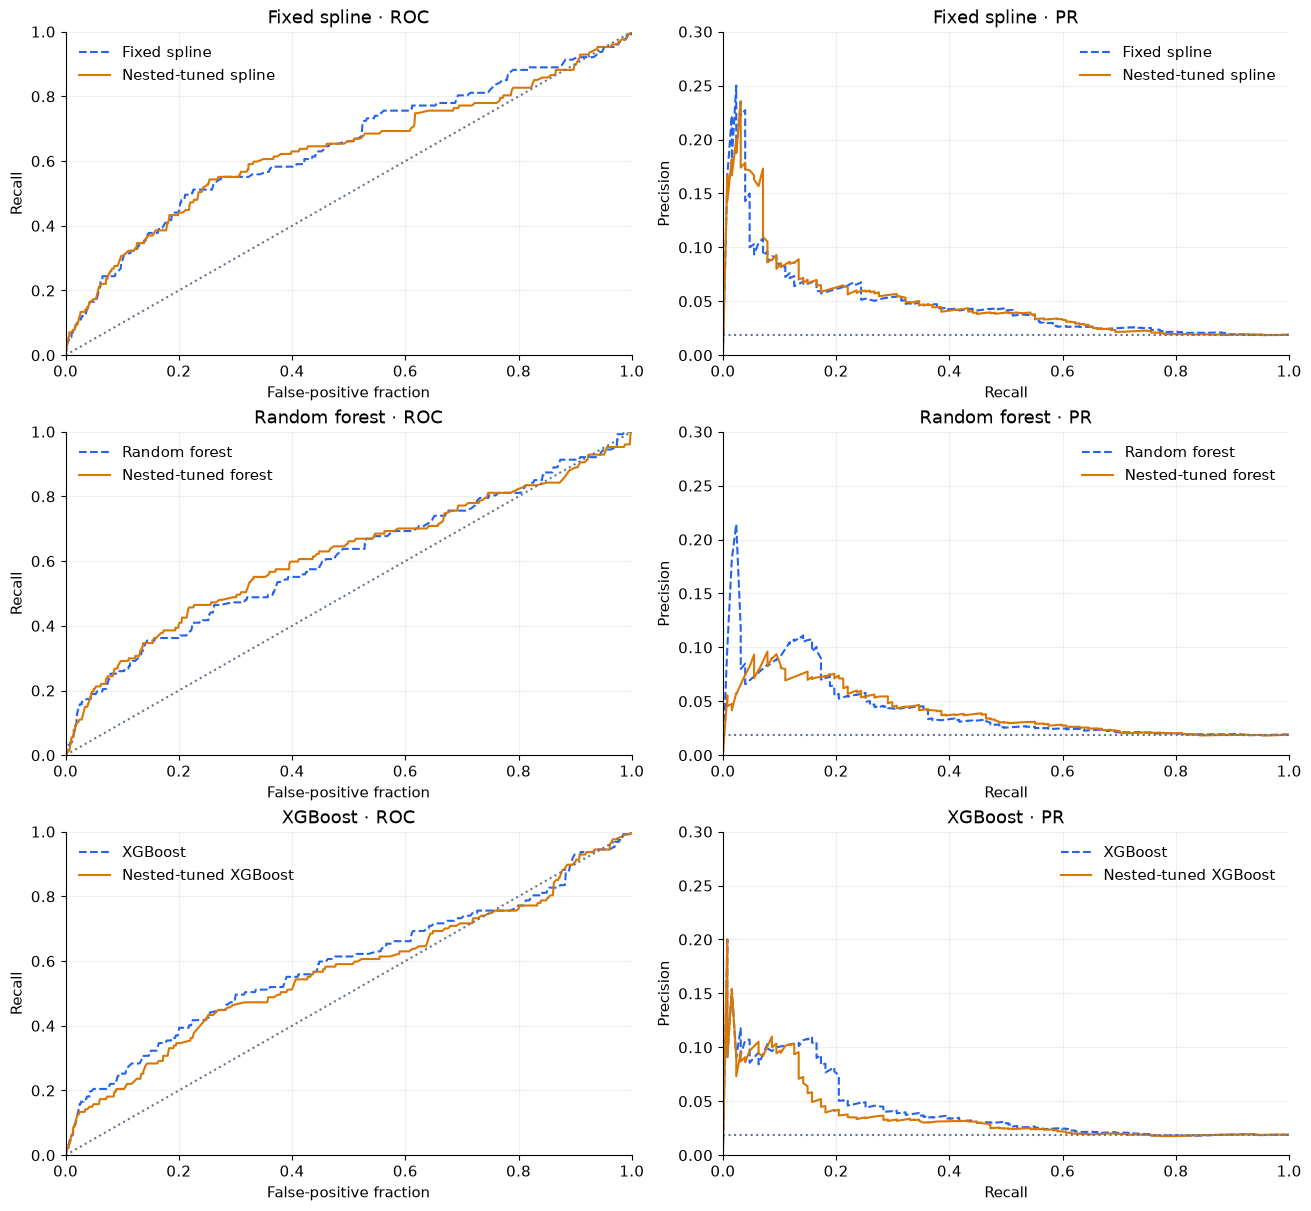

In [7]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(3, 2, figsize=(13, 12), layout="constrained")
for row, pair in enumerate(families):
    for version, name in enumerate(pair):
        color, style = ("#2563eb", "--") if version == 0 else ("#d97706", "-")
        fpr, tpr, _ = roc_curve(frame.target, scores[name]); precision, recall, _ = precision_recall_curve(frame.target, scores[name])
        axes[row, 0].plot(fpr, tpr, style, color=color, label=LABELS[name])
        axes[row, 1].plot(recall, precision, style, color=color, label=LABELS[name])
    axes[row, 0].plot([0, 1], [0, 1], ":", color="#64748b")
    axes[row, 1].axhline(frame.target.mean(), linestyle=":", color="#64748b")
    axes[row, 0].set(xlabel="False-positive fraction", ylabel="Recall", title=LABELS[pair[0]] + " · ROC", xlim=(0, 1), ylim=(0, 1))
    axes[row, 1].set(xlabel="Recall", ylabel="Precision", title=LABELS[pair[0]] + " · PR", xlim=(0, 1), ylim=(0, .30))
    for ax in axes[row]: ax.legend(frameon=False); ax.grid(alpha=.2)
finish_figure(fig, "nested_three_family_roc_pr")

## 7. Collect fold-level improvements, ties and losses

A mean change can hide different directions across patient folds. Count improved/tied/worse folds and report AP/AUC changes without claiming that five reused folds establish repeatable superiority. Recipe selection is training-only, but wider development model exploration still limits final conclusions.

In [8]:
folds = metrics.loc[metrics.scope.eq("fold")].pivot(index="fold", columns="model", values="average_precision")
rows = []
for fixed, tuned in families:
    differences = folds[tuned] - folds[fixed]
    ties = np.isclose(differences, 0)
    rows.append({"family": LABELS[fixed], "mean_fold_AP_change": mean.loc[tuned, "average_precision"] - mean.loc[fixed, "average_precision"], "mean_fold_AUC_change": mean.loc[tuned, "roc_auc"] - mean.loc[fixed, "roc_auc"], "folds_improved": int(((differences > 0) & ~ties).sum()), "folds_tied": int(ties.sum()), "folds_worse": int(((differences < 0) & ~ties).sum())})
display(pd.DataFrame(rows).round(5))
display(folds.round(5))
display(Markdown("The fixed raw spline remains the prescribed metadata comparator. Any change in the final procedure requires a separate declared experiment; these searches never inspect reserved-test labels."))

,family,mean_fold_AP_change,mean_fold_AUC_change,folds_improved,folds_tied,folds_worse
0,Fixed spline,0.00397,-0.01260,3,0,2
1,Random forest,-0.00272,0.02354,1,0,4
2,XGBoost,-0.00649,-0.02572,2,1,2


model,random_forest,random_forest_tuned,spline_raw,spline_tuned,xgboost,xgboost_tuned
fold,,,,,,
0.0,0.04150,0.03903,0.06620,0.06873,0.05221,0.05221
1.0,0.05586,0.04315,0.04603,0.06688,0.06234,0.06100
2.0,0.03241,0.03202,0.03731,0.03571,0.02637,0.02677
3.0,0.06091,0.07238,0.06243,0.05899,0.06896,0.03695
4.0,0.08315,0.07368,0.11224,0.11374,0.08549,0.08598


The fixed raw spline remains the prescribed metadata comparator. Any change in the final procedure requires a separate declared experiment; these searches never inspect reserved-test labels.

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.